# **Hands-on Quantum Computing:**

>Workshop Rule!: Before running a circuit, make a prediciton. Then run and explain what changed.

## 0. Setup

1. Go to your favorite Google Search engine and write `Google Colab`.
2. Click on the [Google Colab Link](https://colab.research.google.com/).
3. Click on the `New notebook`.

You are good to go with the codes below.

⇓

In [1]:
%pip install qiskit
%pip install matplotlib
%pip install pylatexenc


import qiskit
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram
import matplotlib, pylatexenc

print("=" * 100)
print("Qiskit version:", qiskit.__version__)
print("Qiskit Imported Successfully !!")
print("=" * 100)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.9 MB/s eta 0:00:00
Qiskit version: 2.5.2
Qiskit Imported Successfully !!


# Classical Bit
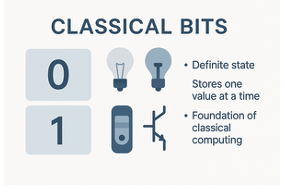

# Quantum Bit (Qubit)
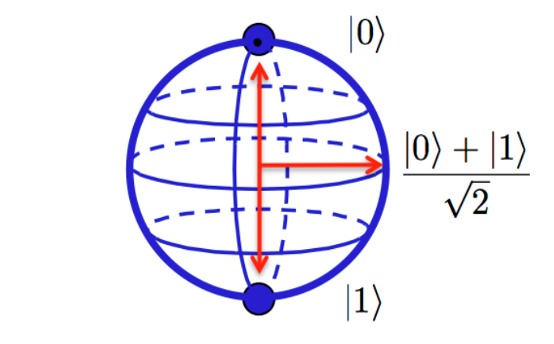

## **1. One Qubit: Start with $\vert 0⟩$**

Please note that
$$|0⟩=\begin{pmatrix}1\\0\end{pmatrix}$$

and

$$|1⟩=\begin{pmatrix}0\\1\end{pmatrix}$$

## 1.1.***X-Gate***

> The Pauli-X gate is the basic quantum equivalent of the classical `NOT gate`, flipping a qubit's state between $\vert0\rangle$ and $\vert1\rangle$.

$$X=\begin{bmatrix}0&1\\1&1\end{bmatrix}$$

$$X⋅|0⟩=\begin{bmatrix}0&1\\1&1\end{bmatrix}⋅\begin{bmatrix}1\\0\end{bmatrix}=\begin{bmatrix}0\\1\end{bmatrix}$$



A newly created qubit is initialized in the state $\vert 0 ⟩$.

We will first apply the **X-gate**, which will flip the computational basis states:
$$\vert 0⟩ → \vert 1 ⟩$$

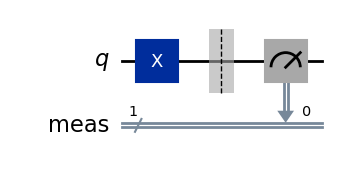

In [2]:
quantum_circuit_X = QuantumCircuit(1)
quantum_circuit_X.x(0)
quantum_circuit_X.measure_all()
display(quantum_circuit_X.draw("mpl"))

{'1': 1024}


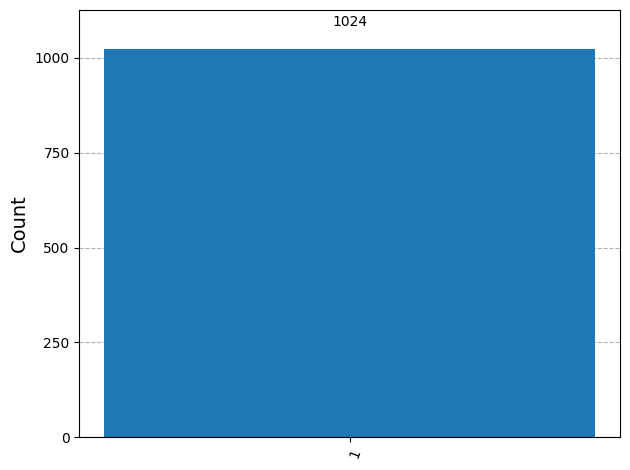

In [3]:
sampler = StatevectorSampler()

resultx = sampler.run([quantum_circuit_X], shots=1024).result()
countsx = resultx[0].data.meas.get_counts()

print(countsx)
plot_histogram(countsx)

**Prediction: What should if we remove the `x(0)` line and measure again?**

Please write your answer below ⬇
------------------------------------------------------

------------------------------------------------------


## 1.2.***Y-Gate***
> A single-qubit quantum operation that rotates the state of a qubit by π radians $180°$ around the $Y-axis$.

The Pauli-Y gate $Y$ or $\sigma _{y}$ is represented by the following $2 × 2$ unitary matrix:

$$Y=\begin{bmatrix}0&-i\\i&0\end{bmatrix}.$$

$$Y⋅|0\rangle=\begin{bmatrix}0&-i\\i&0\end{bmatrix}⋅\begin{bmatrix}0\\1\end{bmatrix}=\begin{bmatrix}0\\-i\end{bmatrix}$$




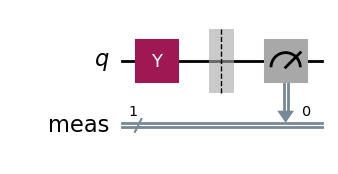

In [4]:
quantum_circuit_Y = QuantumCircuit(1)
quantum_circuit_Y.y(0)
quantum_circuit_Y.measure_all()
display(quantum_circuit_Y.draw("mpl"))

{'1': 1024}


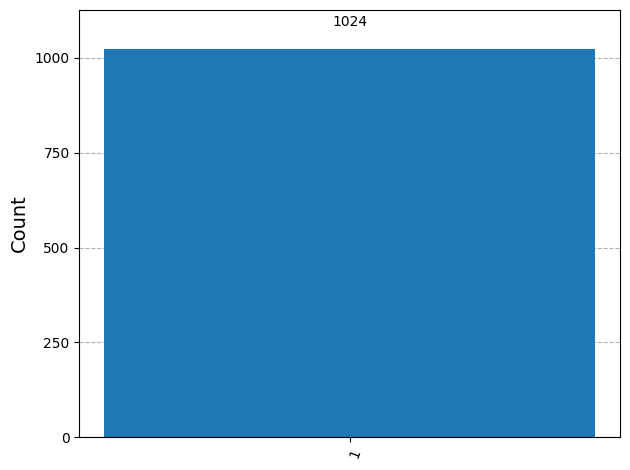

In [5]:
resulty = sampler.run([quantum_circuit_Y], shots=1024).result()
countsy = resulty[0].data.meas.get_counts()

print(countsy)
plot_histogram(countsy)

## 1.3. ***Z-Gate***
> A single-qubit quantum operation that flips the phase of a state by $180°$ degrees around the `Z-axis`.

The $Pauli-Z$ or $σ_z$ gate is represented by following $2 × 2$ unitary matrix:

$$Z=\begin{bmatrix}1&0\\0&-1\end{bmatrix}.$$

$$Z⋅|0\rangle=\begin{bmatrix}1&0\\0&-1\end{bmatrix}⋅\begin{bmatrix}1\\0\end{bmatrix}=\begin{bmatrix}1\\0\end{bmatrix}$$

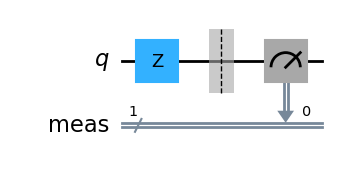

In [6]:
qcz = QuantumCircuit(1)
qcz.z(0)
qcz.measure_all()
display(qcz.draw("mpl"))

{'0': 1024}


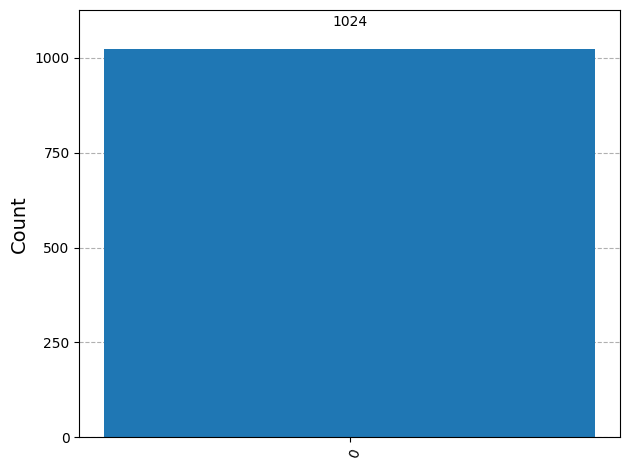

In [7]:
resultz = sampler.run([qcz], shots=1024).result()
countsz = resultz[0].data.meas.get_counts()

print(countsz)
plot_histogram(countsz)

### **How if we apply the** *Z-gate* **to** $|1⟩$ state?:

$$Z⋅|1\rangle=\begin{bmatrix}1&0\\0&-1\end{bmatrix}⋅\begin{bmatrix}0\\1\end{bmatrix}=\begin{bmatrix}0\\-1\end{bmatrix}$$

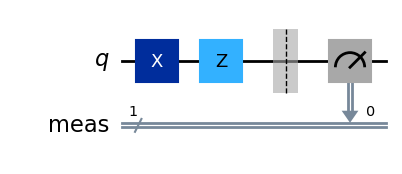

In [8]:
qcz = QuantumCircuit(1)

qcz.x(0)                     # Put into state |1> first
qcz.z(0)                    # Apply Z gate, state becomes -|1>

qcz.measure_all()
display(qcz.draw("mpl"))

{'1': 1024}


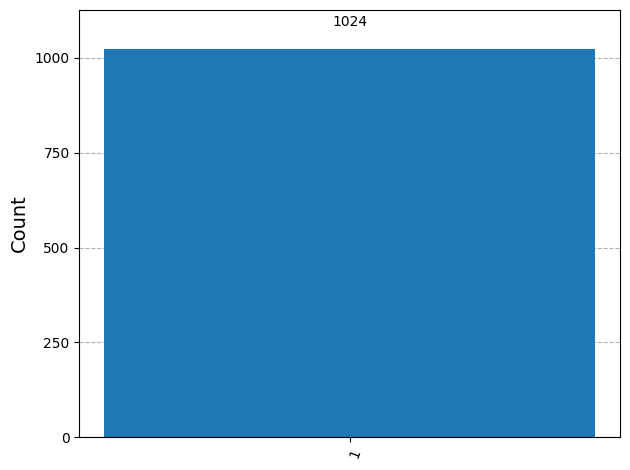

In [9]:
resultz = sampler.run([qcz], shots=1024).result()
countsz = resultz[0].data.meas.get_counts()

print(countsz)
plot_histogram(countsz)

## 2.**Hadamard gate: Create a Superposition**

The **H-gate** transforms the state $|0⟩$ into
$$|0⟩ → \frac{|0 ⟩+|1⟩}{\sqrt 2}.$$

$$H=\begin{bmatrix}1&1\\1&-1\end{bmatrix}$$
When applied to state $|0⟩:$
$$H|0⟩=\frac{1}{\sqrt2}\begin{bmatrix}1&1\\1&-1\end{bmatrix}⋅\begin{bmatrix}1\\0\end{bmatrix}=\frac{1}{\sqrt2}\begin{bmatrix}1\\1\end{bmatrix}=\frac{1}{\sqrt2}\begin{bmatrix}1\\0\end{bmatrix}+\frac{1}{\sqrt2}\begin{bmatrix}0\\1\end{bmatrix}=\frac{1}{\sqrt2}|0⟩+\frac{1}{\sqrt2}|1⟩$$




Or in simple words, this gives approximately $50\% \Rightarrow |0⟩ \qquad$ and $50\% \Rightarrow |1⟩$.

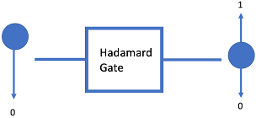

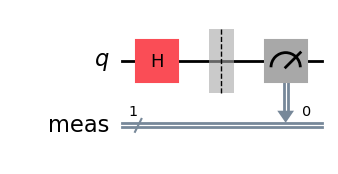

In [10]:
qcH = QuantumCircuit(1)

qcH.h(0)
qcH.measure_all()

display(qcH.draw("mpl"))

{'1': 507, '0': 517}


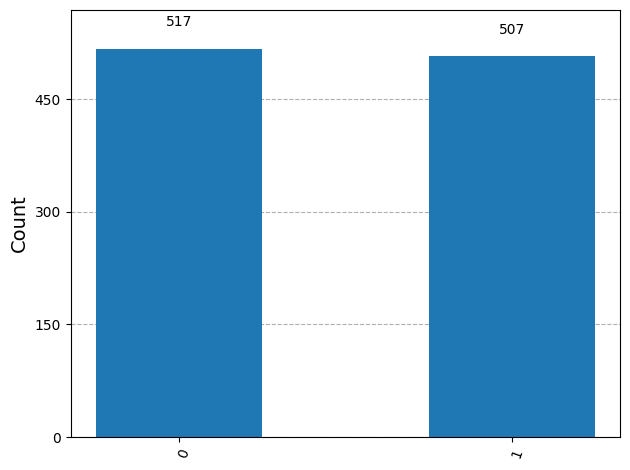

In [11]:
resultH = sampler.run([qcH], shots=1024).result()
countsH = resultH[0].data.meas.get_counts()

print(countsH)
plot_histogram(countsH)

### 2.1.**Mini-experiment: `H-gate` TWICE**

Q. What do you predict for `H → H`?

$$HH=\frac{1}{\sqrt2}\begin{bmatrix}1&1\\1&-1\end{bmatrix}\frac{1}{\sqrt2}\begin{bmatrix}1&1\\1&-1\end{bmatrix}=\frac{1}{2}\begin{bmatrix}1&0\\0&1\end{bmatrix}.$$

Because Hadamard gate is its own inverse,
$$H^2 = I$$
two Hadamard gates return the qubit to its original state.

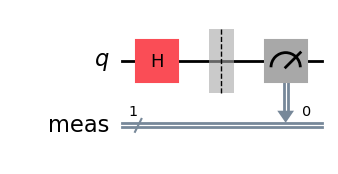

{'0': 501, '1': 523}


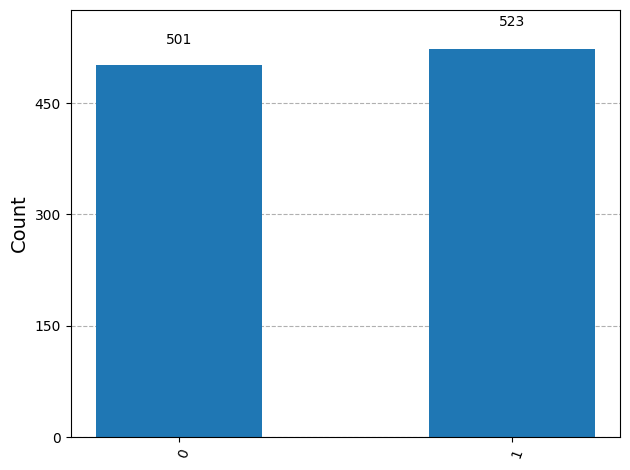

In [12]:
qcH = QuantumCircuit(1)
qcH.h(0)
# Apply the second Hadamard gate below


qcH.measure_all()
display(qcH.draw("mpl"))

result = sampler.run([qcH], shots=1024).result()
counts = result[0].data.meas.get_counts()

print(counts)
plot_histogram(counts)

## 2.2.**Applying H-gate to multiple Qubits**

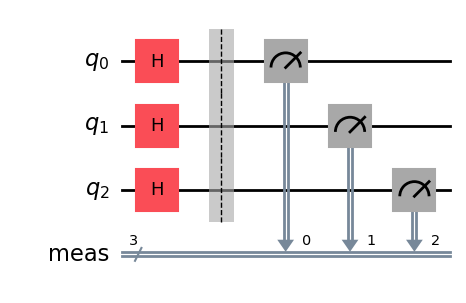

{'000': 115, '111': 125, '011': 132, '100': 145, '001': 144, '110': 114, '101': 124, '010': 125}


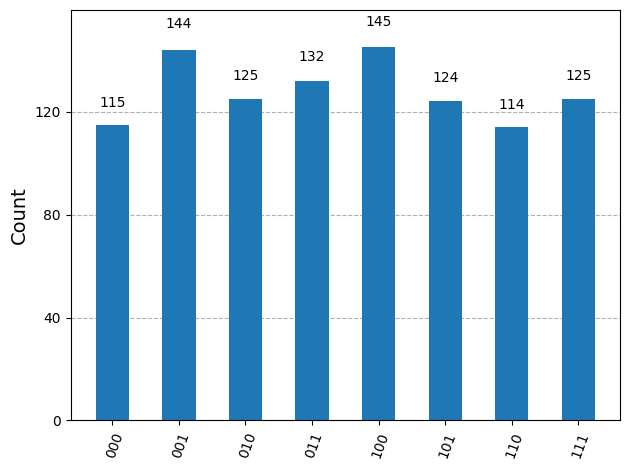

In [13]:
qc_multiple_H = QuantumCircuit(3)

# Apply Hadamard to all 3 qubits
# qc_multiple_H.h([0, 1, 2])
qc_multiple_H.h(0)
qc_multiple_H.h(1)
qc_multiple_H.h(2)

qc_multiple_H.measure_all()

# Draw the circuit
display(qc_multiple_H.draw("mpl"))

sampler = StatevectorSampler()
result = sampler.run([qc_multiple_H], shots=1024).result()

# Get measurement results
counts = result[0].data.meas.get_counts()

print(counts)
plot_histogram(counts)

## 3.**Two Qubits and the CNOT gate**

Now we move to two qubits.

The **CX (CNOT)** gate has:

- a **control** qubit;
- a **target** qubit.

$$
CNOT=\begin{bmatrix}1&0&0&0\\0&1&0&1\\0&0&0&1\\0&0&1&0\end{bmatrix},
$$
so
$$
CNOT⋅|10⟩=\begin{bmatrix}1&0&0&0\\0&1&0&0\\0&0&0&1\\0&0&1&0\end{bmatrix}⋅\begin{bmatrix}0\\0\\1\\0\end{bmatrix}=\begin{bmatrix}0\\0\\0\\1\end{bmatrix}
$$



It flips the `target` only when the `control` is in $|1⟩$.

The circuit below starts in $|00⟩$, creates superposition on qubit `0`, and then applied `CX`.

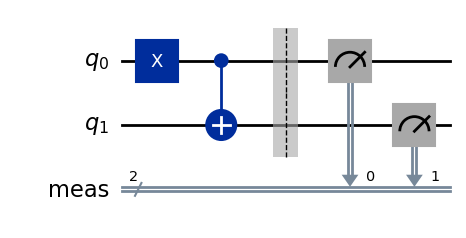

In [14]:
qc_CNOT = QuantumCircuit(2)
qc_CNOT.x(0)                            # Prepare control qubit in |1>
qc_CNOT.cx(0, 1)                        # Apply CNOT

# 2. Add measurements to the circuit
qc_CNOT.measure_all()
display(qc_CNOT.draw("mpl"))

{'11': 1024}


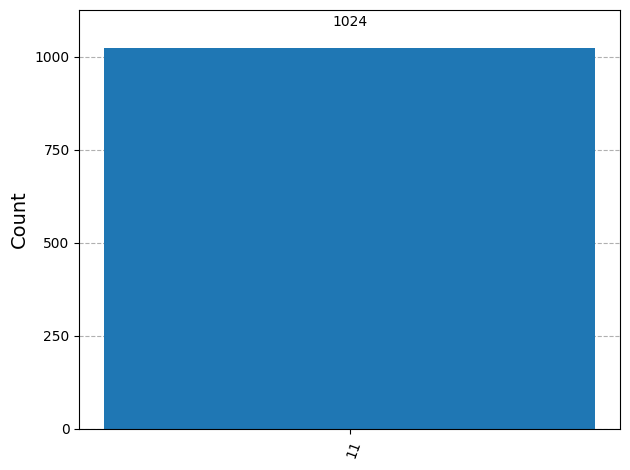

In [15]:
job = sampler.run([qc_CNOT], shots=1024)
result = job.result()[0]


counts = result.data.meas.get_counts()

print(counts)
plot_histogram(counts)

## $\boxed{Bell State}$

The circuit prepares the Bell state
$$|ψ^+⟩=\frac{|00⟩+|11⟩}{\sqrt2}.$$

After measurement, we expect approximately:
- `00` → $50\%$
- `11` → $50\%$
- `01` → approxmately $0\%$
- `10` → approxmately $0\%$

The exact counts fluctuate because we are sampling a finite number of shots.



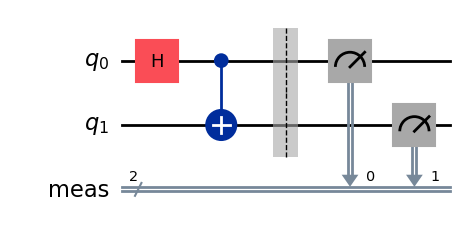


Bell State Output: {'00': 506, '11': 518}


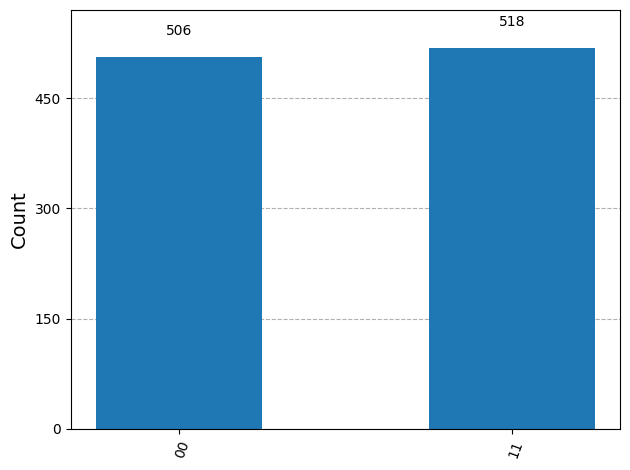

In [16]:
# 1. Initialize a 2-qubit circuit
qc = QuantumCircuit(2)

qc.h(0)          # Apply Hadamard gate to put qubit 0 in a 50/50 superposition
qc.cx(0, 1)      # Apply CNOT gate to entangle qubit 1 with qubit 0

# 3. Add the measurement line
qc.measure_all()
display(qc.draw("mpl"))

job = sampler.run([qc], shots=1024)
result = job.result()


counts = result[0].data.meas.get_counts()
print("\nBell State Output:", counts)
plot_histogram(counts)

### What did we observe?
The outcomes are strongly correlated in the computational basis: when one qubit is measured as $0$, the other is also $0$; when one is measured as $1$, the other is also $1$.

This is the standard two-qubit Bell-State example.

**IMPORTANT:** Do not interpret this is as faster-than-light communication. The point here is the structure of the joint quantum state and its measurement correlation.

## 5. Mini Challenge- change the circuit

### Challenge A
Remove the H-gate. What should happen?

### Challenge B
Keep `H` and `CX` but add:
`qc.x(1)`
before measurement. What happens to the output distribution?

### Challenge C
Try `H → X → H` on one qubit. Predict first.

Use the next cell as your scratch space

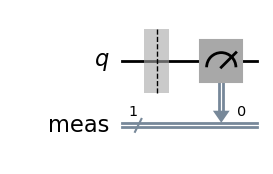

In [17]:
# SCRATCH SPACE
# Example:
qc = QuantumCircuit(1)
# Write your code below



qc.measure_all()

display(qc.draw("mpl"))

## 5.**Combining Two Quantum Circuits**


Circuit 1:


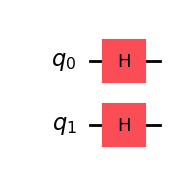

Circuit 2:


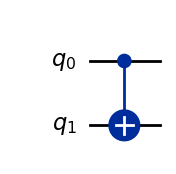

Combined circuit:


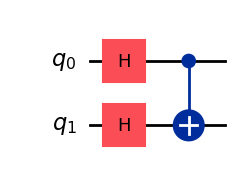

In [18]:
# Circuit 1: Put both qubits into superposition
circuit_1 = QuantumCircuit(2)
circuit_1.h([0, 1])

# Circuit 2: Apply a CNOT gate
circuit_2 = QuantumCircuit(2)
circuit_2.cx(0, 1)

# Display the two circuits separately
print("Circuit 1:")
display(circuit_1.draw("mpl"))

print("Circuit 2:")
display(circuit_2.draw("mpl"))

# Combine Circuit 1 followed by Circuit 2
combined_circuit = circuit_1.compose(circuit_2)

print("Combined circuit:")
display(combined_circuit.draw("mpl"))

## 6.**One useful Qiskit habit**

Most beginner circcuits can be understood with this mental model:
```text
Create QuantumCircuit → Apply Gates → Measure_all() → StateVectorSampler() → Histogram
```

## 7.**Handoff to Grover's Algorithm**

We have now practices the basic ingredients that the next session will use:

- qubits
- quantum gates
- circuit construction
- measurement
- repeated sampling


Grover's Algorithms adds a structured sequences of gates - especially an **oracle** and a **difussion/amplification step** - to turn these basic building blocks into a search algorithm.

### Final Question

> If we can already build a circuit from gates, what else do we need to turn a circuit into an algorithm?

> Answer: A purposefully designed sequence of operations that encodes a computational task.
